# UTS Graf Sains Data: 2.1 Wrangling & EDA dan 2.2 Analytics

Dataset: RetailRocket `events.csv` (Roman Zykov). Notebook ini adalah **file kedua** (soal UTS).
File pertama (`01_Soal_Pendahuluan.ipynb`) berisi tugas pendahuluan 1.1 sampai 1.3.

**Cara menjalankan:** pastikan Neo4j sudah *Running*, lalu pilih *Restart* dan *Run All*.
Password Neo4j diminta lewat kotak input (atau isi variabel lingkungan `NEO4J_PASSWORD`), jadi tidak tersimpan di notebook.

## 0. Persiapan

In [18]:
%pip install -q neo4j pandas numpy scipy networkx matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix, diags
from scipy.sparse.csgraph import connected_components
from tqdm.auto import tqdm
from IPython.display import display, Markdown
from neo4j import GraphDatabase


SRC = r"D:\baru 1\data"    
OUT = "data"               
IMG = "img"                
os.makedirs(OUT, exist_ok=True)
os.makedirs(IMG, exist_ok=True)

URI  = "neo4j://localhost:7687"
USER = "neo4j"
DB   = "neo4j"

# Password dibaca dari file lokal password.txt (tidak ikut diunggah) atau variabel lingkungan NEO4J_PASSWORD
if os.path.exists("password.txt"):
    PASSWORD = open("password.txt", encoding="utf-8").read().strip()
else:
    PASSWORD = os.getenv("NEO4J_PASSWORD", "").strip()
assert PASSWORD, "Password Neo4j tidak ditemukan. Buat file password.txt atau isi variabel lingkungan NEO4J_PASSWORD."


driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
try:
    driver.execute_query("RETURN 1 AS ok", database_=DB)
    print("Terhubung ke database:", DB)
except Exception:
    driver.close()
    raise

def q(cypher, **params):
    records, _, _ = driver.execute_query(cypher, parameters_=params, database_=DB)
    return pd.DataFrame([r.data() for r in records])

def tulis(cypher, **params):
    driver.execute_query(cypher, parameters_=params, database_=DB)

Terhubung ke database: neo4j


# 2.1 Wrangling dan EDA

## No. 1: Menentukan 2 periode waktu (P1 dan P2)

| | Periode | Fungsi |
|---|---|---|
| **P1** | 15 Mei 2015 s.d. 28 Mei 2015 (14 hari) | Fold *training*: membentuk graf dan model |
| **P2** | 29 Mei 2015 s.d. 4 Juni 2015 (7 hari) | Fold *testing*: *ground truth* evaluasi |

In [20]:
P1 = ("2015-05-15", "2015-05-28")   # Fold training  (mulai, selesai) inklusif
P2 = ("2015-05-29", "2015-06-04")   # Fold testing

df = pd.read_csv(os.path.join(SRC, "events.csv"))
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")      # unix epoch (ms) -> datetime UTC
print("Seluruh data:", df.shape, "|", df["dt"].min(), "s.d.", df["dt"].max())

Seluruh data: (2756101, 6) | 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000


## No. 2: Terapkan filter pada `timestamp`, lalu simpan ke `.csv`

In [21]:
def filter_periode(d, mulai, selesai):
    awal  = pd.Timestamp(mulai)
    akhir = pd.Timestamp(selesai) + pd.Timedelta(days=1)    # inklusif sampai akhir hari 'selesai'
    return d[(d["dt"] >= awal) & (d["dt"] < akhir)].copy()

p1 = filter_periode(df, *P1)
p2 = filter_periode(df, *P2)

assert p1["dt"].max() < p2["dt"].min(), "P1 harus terjadi sebelum P2"

for nama, d, rentang in [("P1", p1, P1), ("P2", p2, P2)]:
    print(f"{nama} {rentang}: {len(d):,} event | {d['visitorid'].nunique():,} visitor | "
          f"{d['itemid'].nunique():,} item | {d['event'].value_counts().to_dict()}")

kolom = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
for nama, d in [("p1", p1), ("p2", p2)]:
    out = d[kolom].copy()
    out["transactionid"] = out["transactionid"].astype("Int64")     # tulis sebagai bilangan bulat (bukan 1234.0)
    path = os.path.join(OUT, f"events_{nama}.csv")
    out.to_csv(path, index=False)
    print("Disimpan:", path, f"({os.path.getsize(path)/1e6:.1f} MB)")

P1 ('2015-05-15', '2015-05-28'): 304,718 event | 163,126 visitor | 80,778 item | {'view': 295268, 'addtocart': 7111, 'transaction': 2339}
P2 ('2015-05-29', '2015-06-04'): 145,321 event | 79,680 visitor | 50,369 item | {'view': 140674, 'addtocart': 3480, 'transaction': 1167}
Disimpan: data\events_p1.csv (10.7 MB)
Disimpan: data\events_p2.csv (5.1 MB)


## Persiapan graf: impor data P1 ke Neo4j
Graf yang dianalisis adalah **graf P1** (training). Skema: `(:Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(:Item)`.

Kode mengikuti contoh soal 1.3 (impor *batch* dengan `UNWIND`). Perbedaannya: pemilihan jenis relasi memakai `FOREACH` + `CASE`
(hasilnya sama dengan `CALL {... UNION ALL ...}` pada soal, tetapi lebih aman di berbagai versi Neo4j).

In [22]:
FORCE_RESET = False   # True: paksa kosongkan database lalu impor ulang (HATI-HATI: menghapus semua isi DB)
batch_size  = 5000

def kosongkan_database():
    while True:
        recs, _, _ = driver.execute_query(
            "MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c", database_=DB)
        if recs[0]["c"] == 0:
            break

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    FOREACH (ignore IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
    FOREACH (ignore IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
    FOREACH (ignore IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i))
    """
    tx.run(cypher_query, batch=batch)

csv_p1 = os.path.join(OUT, "events_p1.csv")
n_p1 = len(p1)
n_node_p1 = p1["visitorid"].nunique() + p1["itemid"].nunique()

n_rel  = int(q("MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() RETURN count(r) AS n")["n"].iloc[0])
n_node = int(q("MATCH (n) RETURN count(n) AS n")["n"].iloc[0])

if not FORCE_RESET and n_rel == n_p1 and n_node == n_node_p1:
    # graf P1 sudah ada: cukup bersihkan relasi hasil analisis sebelumnya agar kondisi "sebelum similarity" benar
    tulis("MATCH ()-[x:SIMILAR|RECOMMENDED]->() DELETE x")
    print(f"Graf P1 sudah ada ({n_node:,} simpul, {n_rel:,} relasi). Impor dilewati.")
else:
    print(f"Graf P1 belum ada (database berisi {n_node:,} simpul dan {n_rel:,} relasi interaksi). Database dikosongkan lalu P1 diimpor ...")
    kosongkan_database()
    with driver.session(database=DB) as session:
        create_constraints(session)
        print(f"Membaca file data dari: {csv_p1}")
        chunks = pd.read_csv(csv_p1, chunksize=batch_size)
        total_chunks = (n_p1 // batch_size) + 1
        t0 = time.time()
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            # Membersihkan data null/NaN pada transactionid
            chunk["transactionid"] = chunk["transactionid"].fillna(-1).astype("int64").astype(str).replace("-1", "")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
        print(f"Proses impor berhasil ({time.time()-t0:.0f} detik).")

Graf P1 sudah ada (243,904 simpul, 304,718 relasi). Impor dilewati.


## No. 3: Komposisi subgraph (jenis simpul dan jumlahnya)

**Penjelasan Cypher**
- `MATCH (n)` mencocokkan **semua simpul** pada graf.
- `labels(n)[0]` mengambil label pertama simpul (`Visitor` atau `Item`).
- `count(n)` adalah fungsi agregat. Cypher otomatis mengelompokkan menurut kolom non-agregat (`labels(n)[0]`), mirip `GROUP BY` pada SQL.
- `MATCH ()-[r]->()` mencocokkan **semua relasi berarah**, dan `type(r)` memberi jenis relasinya (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).
- Query ketiga menghitung pola `(Label)-[RELASI]->(Label)` untuk melihat skema graf.

In [23]:
q_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
q_skema = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
"""
komp_node = q(q_node)
komp_rel  = q(q_rel)
display(Markdown("**Jumlah simpul per jenis**")); display(komp_node)
display(Markdown("**Jumlah relasi per jenis**")); display(komp_rel)
display(Markdown("**Skema graf**"));              display(q(q_skema))

# Validasi silang terhadap data CSV (P1)
n_visitor = int(komp_node.loc[komp_node.jenis_simpul == "Visitor", "jumlah"].iloc[0])
n_item    = int(komp_node.loc[komp_node.jenis_simpul == "Item", "jumlah"].iloc[0])
assert n_visitor == p1["visitorid"].nunique() and n_item == p1["itemid"].nunique()
assert int(komp_rel["jumlah"].sum()) == len(p1)
print(f"Valid: {n_visitor:,} Visitor + {n_item:,} Item = {n_visitor+n_item:,} simpul; "
      f"{int(komp_rel['jumlah'].sum()):,} relasi = jumlah baris P1.")

**Jumlah simpul per jenis**

,jenis_simpul,jumlah
0,Visitor,163126
1,Item,80778


**Jumlah relasi per jenis**

,jenis_relasi,jumlah
0,VIEWED,295268
1,ADDED_TO_CART,7111
2,BOUGHT,2339


**Skema graf**

,dari,relasi,ke,jumlah
0,Visitor,VIEWED,Item,295268
1,Visitor,ADDED_TO_CART,Item,7111
2,Visitor,BOUGHT,Item,2339


Valid: 163,126 Visitor + 80,778 Item = 243,904 simpul; 304,718 relasi = jumlah baris P1.


## No. 4: Vector Space Modelling (VSM) simpul **User** (`Visitor`)

Graf interaksi bersifat **bipartit** (Visitor ke Item). Pada VSM, setiap simpul diubah menjadi vektor:
- **Vektor User**: baris matriks `M` (user × item). Dimensi vektor = **jumlah item**, nilai = bobot interaksi.
- Bobot interaksi: `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5 (makin kuat sinyal minat, makin besar bobotnya). Bobot diakumulasi bila user berinteraksi berulang pada item yang sama.
- Untuk menghitung kemiripan dipakai *cosine similarity* (vektor dinormalisasi L2).

Data diambil **dari Neo4j** (graf), diagregasi per pasangan (visitor, item, jenis relasi).

In [24]:
q_edges = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item, type(r) AS rel, count(r) AS n
"""
edges = q(q_edges)
assert int(edges["n"].sum()) == len(p1), "jumlah relasi dari Neo4j harus sama dengan jumlah baris P1"

BOBOT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["rel"].map(BOBOT) * edges["n"]
d = edges.groupby(["user", "item"], as_index=False)["w"].sum()

u_idx = {u: k for k, u in enumerate(sorted(d["user"].unique()))}
i_idx = {x: k for k, x in enumerate(sorted(d["item"].unique()))}
inv_u = {k: u for u, k in u_idx.items()}
inv_i = {k: x for x, k in i_idx.items()}

M = csr_matrix((d["w"].astype(float).values,
                (d["user"].map(u_idx).values, d["item"].map(i_idx).values)),
               shape=(len(u_idx), len(i_idx)))
print("Pasangan (user, item) unik:", len(d))
print("Matriks interaksi M (user x item):", M.shape)

Pasangan (user, item) unik: 239536
Matriks interaksi M (user x item): (163126, 80778)


In [25]:
def ringkas_vsm(X, nama):
    """Karakteristik VSM untuk matriks X (baris = vektor yang dimodelkan)."""
    X = X.tocsr()
    nnz_vec = np.diff(X.indptr)
    norma = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
    dense_gb = X.shape[0] * X.shape[1] * 8 / 1e9
    csr_mb = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6
    return pd.Series({
        "Jumlah vektor (baris)": f"{X.shape[0]:,}",
        "Dimensi vektor (kolom)": f"{X.shape[1]:,}",
        "Shape": str(X.shape),
        "Elemen tak-nol (nnz)": f"{X.nnz:,}",
        "Kepadatan (density)": f"{X.nnz / (X.shape[0] * X.shape[1]):.2e}",
        "Sparsity": f"{100 * (1 - X.nnz / (X.shape[0] * X.shape[1])):.4f}%",
        "Vektor dengan tepat 1 elemen tak-nol": f"{(nnz_vec == 1).mean():.1%}",
        "nnz per vektor: rata-rata / median / maks": f"{nnz_vec.mean():.2f} / {np.median(nnz_vec):.0f} / {nnz_vec.max()}",
        "Norma L2 rata-rata": f"{norma.mean():.2f}",
        "Memori jika dense (float64)": f"{dense_gb:,.1f} GB",
        "Memori format CSR": f"{csr_mb:.1f} MB",
    }, name=nama)

vsm_user = ringkas_vsm(M, "VSM User")
display(vsm_user.to_frame())

# contoh satu vektor user: user paling aktif
u_top = int(np.argmax(np.diff(M.indptr)))
vek = M[u_top]
contoh = pd.DataFrame({"itemId": [inv_i[j] for j in vek.indices], "bobot": vek.data}).sort_values("bobot", ascending=False)
print(f"Contoh vektor user {inv_u[u_top]}: {vek.nnz} dimensi tak-nol dari {M.shape[1]:,} dimensi. 8 teratas:")
display(contoh.head(8))

,VSM User
Jumlah vektor (baris),"163,126"
Dimensi vektor (kolom),"80,778"
Shape,"(163126, 80778)"
Elemen tak-nol (nnz),"239,536"
Kepadatan (density),1.82e-05
Sparsity,99.9982%
Vektor dengan tepat 1 elemen tak-nol,81.2%
nnz per vektor: rata-rata / median / maks,1.47 / 1 / 722
Norma L2 rata-rata,1.52
Memori jika dense (float64),105.4 GB


Contoh vektor user 286616: 722 dimensi tak-nol dari 80,778 dimensi. 8 teratas:


,itemId,bobot
521,318333,24.0
26,14758,19.0
409,250962,17.0
421,259962,15.0
662,418408,15.0
345,212743,14.0
350,215522,14.0
633,397692,13.0


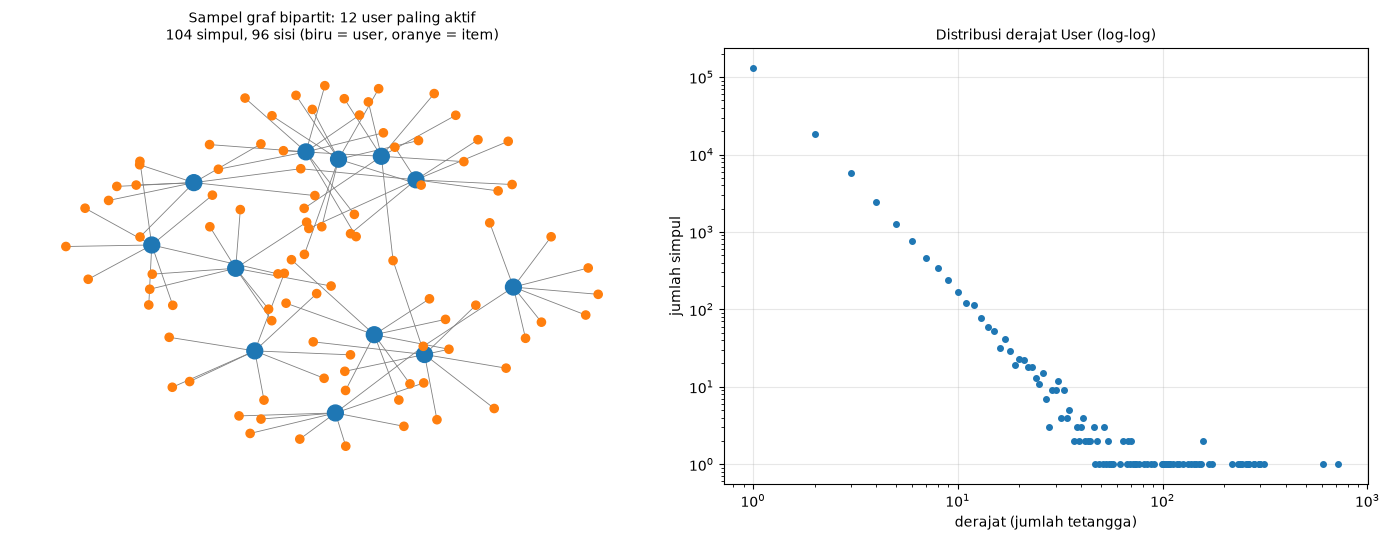

In [26]:
def sampel_bipartit(d, sisi, n_seed=12, maks=8, min_deg_lawan=1):
    """Ambil sampel graf bipartit: n_seed simpul 'sisi' paling aktif beserta tetangga terkuatnya."""
    lawan = "item" if sisi == "user" else "user"
    deg_lawan = d.groupby(lawan).size()
    dd = d[d[lawan].map(deg_lawan) >= min_deg_lawan]
    seeds = d.groupby(sisi).size().nlargest(n_seed).index
    return dd[dd[sisi].isin(seeds)].sort_values("w", ascending=False).groupby(sisi).head(maks)

def gambar_bipartit(ax, sub, sisi, judul):
    G = nx.Graph()
    for r in sub.itertuples():
        G.add_edge(("user", r.user), ("item", r.item), w=r.w)
    warna  = ["tab:blue" if n[0] == "user" else "tab:orange" for n in G.nodes]
    ukuran = [130 if n[0] == sisi else 35 for n in G.nodes]
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42, k=0.35), ax=ax, node_color=warna,
                     node_size=ukuran, with_labels=False, width=0.6, edge_color="gray")
    ax.set_title(f"{judul}\n{G.number_of_nodes()} simpul, {G.number_of_edges()} sisi (biru = user, oranye = item)", fontsize=10)
    ax.set_axis_off()

def hist_derajat(ax, deg, judul, warna):
    vals, cnt = np.unique(deg, return_counts=True)
    ax.loglog(vals, cnt, "o", ms=4, color=warna)
    ax.set_xlabel("derajat (jumlah tetangga)"); ax.set_ylabel("jumlah simpul")
    ax.set_title(judul, fontsize=10); ax.grid(alpha=0.3)

deg_user = np.diff(M.indptr)                       # item per user
deg_item = np.diff(M.T.tocsr().indptr)             # user per item

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
gambar_bipartit(ax[0], sampel_bipartit(d, "user"), "user", "Sampel graf bipartit: 12 user paling aktif")
hist_derajat(ax[1], deg_user, "Distribusi derajat User (log-log)", "tab:blue")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "vsm_user.png"), dpi=120); plt.show()

**Karakteristik VSM User** (lihat tabel dan gambar di atas)
- Vektor user berdimensi sebesar **jumlah item** (puluhan ribu) dan jumlah vektornya sebesar jumlah visitor (ratusan ribu), sehingga matriksnya sangat besar.
- Matriks **sangat jarang (sparse)**: hampir seluruh elemen bernilai nol. Disimpan *dense* butuh ratusan GB, dengan format CSR hanya beberapa MB. Maka wajib memakai matriks *sparse*.
- Mayoritas user hanya berinteraksi dengan **1 item**, sehingga vektornya hanya punya satu elemen tak-nol. Distribusi derajat berbentuk **ekor panjang (long tail)**: sedikit user sangat aktif (bisa ratusan item, kemungkinan *crawler/bot* atau pembeli intensif), sisanya hampir pasif.
- Konsekuensinya, informasi untuk membandingkan dua user sangat terbatas (vektornya hampir tidak beririsan).

## No. 5: VSM simpul **Item**

Sisi item adalah **transpos** dari sisi user:
- **Vektor Item**: kolom matriks `M` (baris pada `Mᵀ`). Dimensi vektor = **jumlah visitor**, nilai = bobot interaksi visitor terhadap item tersebut.

,VSM User,VSM Item
Jumlah vektor (baris),"163,126","80,778"
Dimensi vektor (kolom),"80,778","163,126"
Shape,"(163126, 80778)","(80778, 163126)"
Elemen tak-nol (nnz),"239,536","239,536"
Kepadatan (density),1.82e-05,1.82e-05
Sparsity,99.9982%,99.9982%
Vektor dengan tepat 1 elemen tak-nol,81.2%,55.2%
nnz per vektor: rata-rata / median / maks,1.47 / 1 / 722,2.97 / 1 / 314
Norma L2 rata-rata,1.52,2.15
Memori jika dense (float64),105.4 GB,105.4 GB


Contoh vektor item 370653 (item paling populer): 314 dimensi tak-nol dari 163,126 dimensi. 8 teratas:


,visitorId,bobot
273,1273184,8.0
186,899237,4.0
138,704565,3.0
41,221685,3.0
235,1107084,3.0
288,1329174,3.0
32,157594,2.0
279,1283003,2.0


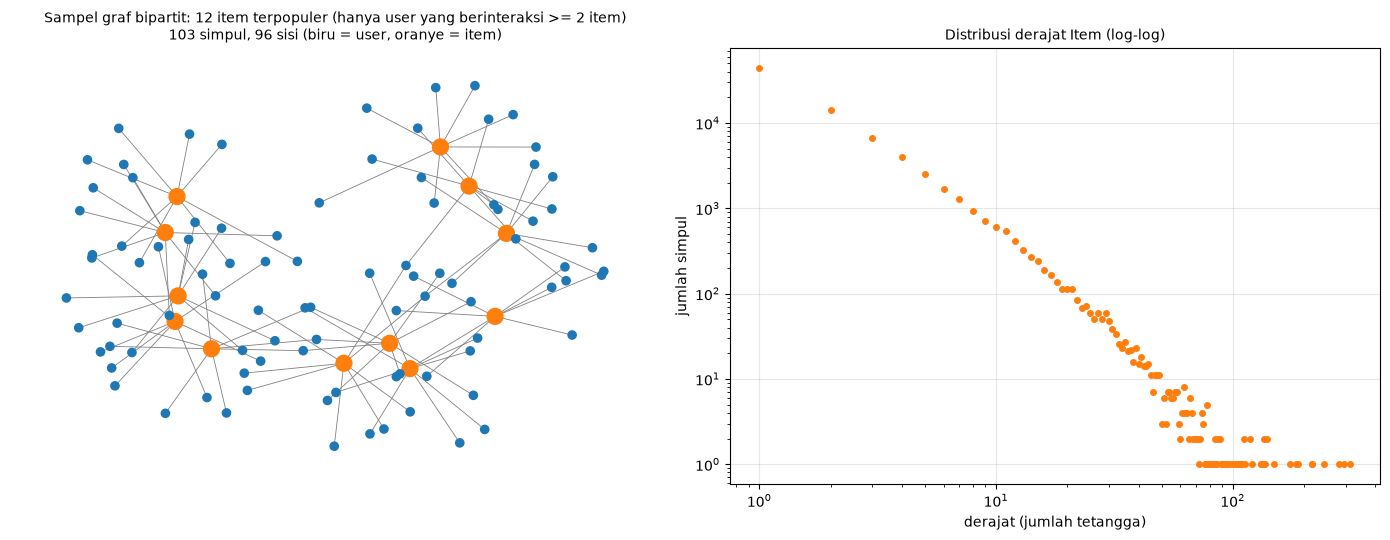

In [27]:
Mt = M.T.tocsr()                                   # item x user
vsm_item = ringkas_vsm(Mt, "VSM Item")
display(pd.concat([vsm_user, vsm_item], axis=1))

i_top = int(np.argmax(np.diff(Mt.indptr)))
vek = Mt[i_top]
contoh = pd.DataFrame({"visitorId": [inv_u[j] for j in vek.indices], "bobot": vek.data}).sort_values("bobot", ascending=False)
print(f"Contoh vektor item {inv_i[i_top]} (item paling populer): {vek.nnz} dimensi tak-nol dari {Mt.shape[1]:,} dimensi. 8 teratas:")
display(contoh.head(8))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
gambar_bipartit(ax[0], sampel_bipartit(d, "item", min_deg_lawan=2), "item",
                "Sampel graf bipartit: 12 item terpopuler (hanya user yang berinteraksi >= 2 item)")
hist_derajat(ax[1], deg_item, "Distribusi derajat Item (log-log)", "tab:orange")
plt.tight_layout(); plt.savefig(os.path.join(IMG, "vsm_item.png"), dpi=120); plt.show()

**Karakteristik VSM Item**
- Vektor item berdimensi sebesar **jumlah visitor**, jauh lebih panjang daripada vektor user, tetapi jumlah vektornya (item) hanya separuh jumlah user.
- Matriks juga sangat *sparse*, dengan distribusi derajat berekor panjang: sedikit item sangat populer, banyak item hanya disentuh 1 user.
- Item yang populer punya vektor yang **lebih kaya** (puluhan sampai ratusan user), sehingga lebih mudah dibandingkan dengan item lain lewat user yang sama (*co-interaction*).
- Pada gambar (hanya user yang berinteraksi dengan >= 2 item), terlihat user-user ini menjadi **penghubung antar item**. Merekalah yang membentuk kemiripan item.

## No. 6: Proyeksi mana yang lebih baik (efektif dan efisien)?

Graf bipartit dapat diproyeksikan ke satu sisi saja:
- **Proyeksi User-User**: `B · Bᵀ`, dua user terhubung jika berinteraksi dengan item yang sama.
- **Proyeksi Item-Item**: `Bᵀ · B`, dua item terhubung jika diinteraksikan oleh user yang sama.

(`B` = versi biner dari `M`.) Keduanya dihitung dan dibandingkan secara empiris.

In [28]:
B = (M > 0).astype(np.int32).tocsr()

def proyeksi(Bm, nama):
    t0 = time.time()
    P = (Bm @ Bm.T).tocsr()
    waktu = time.time() - t0
    n = P.shape[0]
    P_off = P.copy(); P_off.setdiag(0); P_off.eliminate_zeros()        # buang loop diri
    deg = np.diff(P_off.indptr)
    n_comp, label = connected_components(P_off, directed=False)
    ukuran_comp = np.bincount(label)
    mem = (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6
    return P_off, pd.Series({
        "Jumlah simpul": f"{n:,}",
        "Jumlah sisi (tanpa loop)": f"{P_off.nnz // 2:,}",
        "Density": f"{P_off.nnz / (n * (n - 1)):.2e}",
        "Simpul terisolasi": f"{(deg == 0).sum():,} ({(deg == 0).mean():.1%})",
        "Rata-rata derajat": f"{deg.mean():.1f}",
        "Jumlah komponen terhubung": f"{n_comp:,}",
        "Komponen terbesar": f"{ukuran_comp.max():,} simpul ({ukuran_comp.max() / n:.1%})",
        "Memori matriks": f"{mem:.1f} MB",
        "Waktu hitung": f"{waktu:.2f} detik",
    }, name=nama), dict(n=n, sisi=P_off.nnz // 2, iso=(deg == 0).mean(), mem=mem, waktu=waktu, comp=ukuran_comp.max() / n)

P_uu, tab_uu, st_uu = proyeksi(B, "User-User")
P_ii, tab_ii, st_ii = proyeksi(B.T.tocsr(), "Item-Item")
display(pd.concat([tab_uu, tab_ii], axis=1))

,User-User,Item-Item
Jumlah simpul,"163,126","80,778"
Jumlah sisi (tanpa loop),"1,585,929","1,335,142"
Density,1.19e-04,4.09e-04
Simpul terisolasi,"30,080 (18.4%)","38,684 (47.9%)"
Rata-rata derajat,19.4,33.1
Jumlah komponen terhubung,"42,161","42,161"
Komponen terbesar,"93,654 simpul (57.4%)","33,435 simpul (41.4%)"
Memori matriks,27.3 MB,22.3 MB
Waktu hitung,0.09 detik,0.07 detik


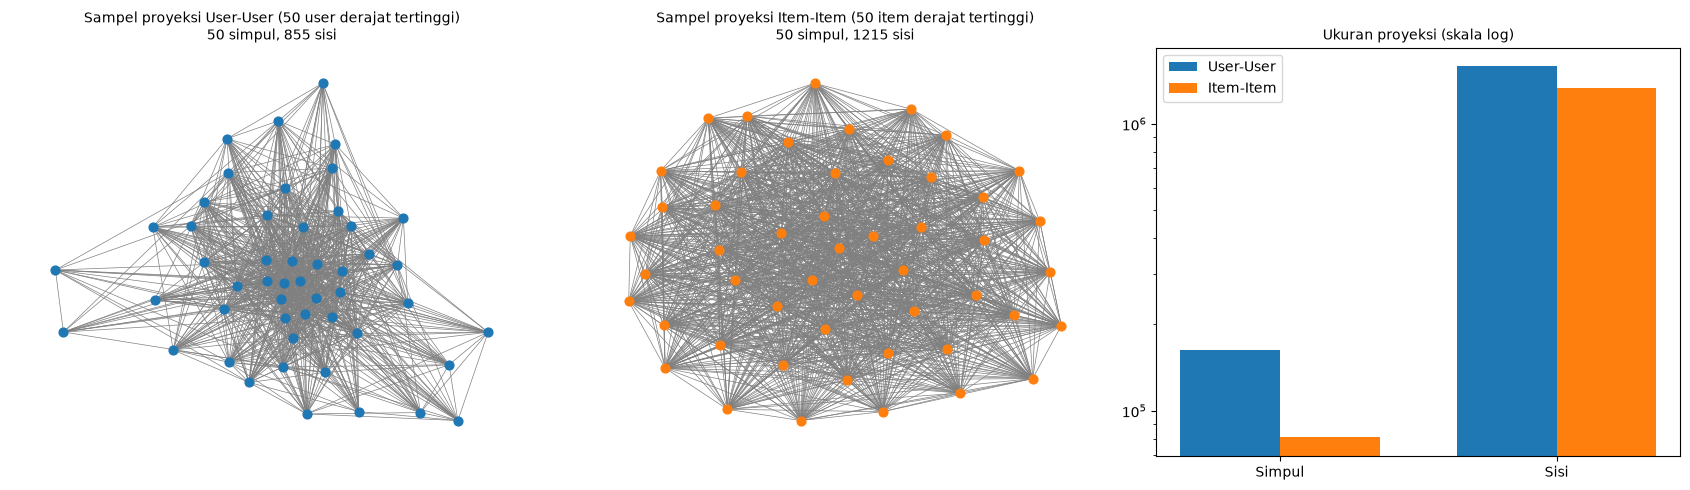

In [29]:
# Sampel graf proyeksi (50 simpul berderajat tertinggi) dan perbandingan ukuran
def gambar_proyeksi(ax, P, label_fn, judul, warna, n_top=50):
    deg = np.diff(P.indptr)
    top = np.argsort(-deg)[:n_top]
    sub = P[top][:, top]
    G = nx.from_scipy_sparse_array(sub)
    G.remove_nodes_from(list(nx.isolates(G)))
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=42, k=0.4), ax=ax, node_size=40, node_color=warna,
                     with_labels=False, width=0.5, edge_color="gray")
    ax.set_title(f"{judul}\n{G.number_of_nodes()} simpul, {G.number_of_edges()} sisi", fontsize=10); ax.set_axis_off()

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
gambar_proyeksi(ax[0], P_uu, None, "Sampel proyeksi User-User (50 user derajat tertinggi)", "tab:blue")
gambar_proyeksi(ax[1], P_ii, None, "Sampel proyeksi Item-Item (50 item derajat tertinggi)", "tab:orange")
kategori = ["Simpul", "Sisi"]
ax[2].bar(np.arange(2) - 0.18, [st_uu["n"], st_uu["sisi"]], 0.36, label="User-User", color="tab:blue")
ax[2].bar(np.arange(2) + 0.18, [st_ii["n"], st_ii["sisi"]], 0.36, label="Item-Item", color="tab:orange")
ax[2].set_xticks(range(2)); ax[2].set_xticklabels(kategori); ax[2].set_yscale("log"); ax[2].legend()
ax[2].set_title("Ukuran proyeksi (skala log)", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "proyeksi.png"), dpi=120); plt.show()

In [30]:
display(Markdown(f"""
### Kesimpulan No. 6: proyeksi **Item-Item** lebih baik

| Kriteria | User-User | Item-Item | Pemenang |
|---|---|---|---|
| Jumlah simpul | {st_uu['n']:,} | {st_ii['n']:,} | Item-Item ({st_uu['n']/st_ii['n']:.1f}x lebih sedikit) |
| Jumlah sisi | {st_uu['sisi']:,} | {st_ii['sisi']:,} | {'Item-Item' if st_ii['sisi'] < st_uu['sisi'] else 'User-User'} |
| Memori matriks | {st_uu['mem']:.1f} MB | {st_ii['mem']:.1f} MB | {'Item-Item' if st_ii['mem'] < st_uu['mem'] else 'User-User'} |
| Simpul terisolasi | {st_uu['iso']:.1%} | {st_ii['iso']:.1%} | {'Item-Item' if st_ii['iso'] < st_uu['iso'] else 'User-User'} |

**Alasan (efisiensi):** proyeksi Item-Item memiliki simpul dan sisi lebih sedikit sehingga lebih hemat memori dan waktu.

**Alasan (efektivitas):**
1. Mayoritas visitor hanya berinteraksi dengan 1 item, sehingga kemiripan antar-user sebagian besar hanya terbentuk lewat satu item populer dan **kurang informatif** (bias ke item populer).
2. Katalog item relatif **stabil**, sedangkan user selalu bertambah. Kemiripan item dapat dihitung sekali dan dipakai untuk user baru (*cold-start*), asalkan user itu punya minimal satu interaksi.
3. Kemiripan item-item langsung menjawab tujuan UTS: **merekomendasikan item** (dasar item-based KNN pada 2.2).

**Catatan trade-off (jujur):** proyeksi Item-Item memiliki lebih banyak simpul terisolasi (item yang hanya disentuh visitor berinteraksi 1 item tidak punya tetangga), sehingga item tersebut tidak dapat direkomendasikan lewat kemiripan. Sebaliknya, proyeksi User-User terlihat lebih "terhubung" tetapi sambungannya banyak lewat item populer yang sama (kurang informatif). Bukti pada evaluasi 2.2: User-KNN sering gagal mengisi daftar top-5 (rata-rata panjang daftar jauh di bawah 5), sedangkan Item-KNN hampir selalu terisi. Namun ini bukan bukti bahwa Item-KNN lebih akurat (lihat catatan akurasi setelah evaluasi di 2.2 No. 2).

Karena itu, perhitungan similarity di No. 7 dan KNN di 2.2 memakai **proyeksi Item-Item**.
"""))


### Kesimpulan No. 6: proyeksi **Item-Item** lebih baik

| Kriteria | User-User | Item-Item | Pemenang |
|---|---|---|---|
| Jumlah simpul | 163,126 | 80,778 | Item-Item (2.0x lebih sedikit) |
| Jumlah sisi | 1,585,929 | 1,335,142 | Item-Item |
| Memori matriks | 27.3 MB | 22.3 MB | Item-Item |
| Simpul terisolasi | 18.4% | 47.9% | User-User |

**Alasan (efisiensi):** proyeksi Item-Item memiliki simpul dan sisi lebih sedikit sehingga lebih hemat memori dan waktu.

**Alasan (efektivitas):**
1. Mayoritas visitor hanya berinteraksi dengan 1 item, sehingga kemiripan antar-user sebagian besar hanya terbentuk lewat satu item populer dan **kurang informatif** (bias ke item populer).
2. Katalog item relatif **stabil**, sedangkan user selalu bertambah. Kemiripan item dapat dihitung sekali dan dipakai untuk user baru (*cold-start*), asalkan user itu punya minimal satu interaksi.
3. Kemiripan item-item langsung menjawab tujuan UTS: **merekomendasikan item** (dasar item-based KNN pada 2.2).

**Catatan trade-off (jujur):** proyeksi Item-Item memiliki lebih banyak simpul terisolasi (item yang hanya disentuh visitor berinteraksi 1 item tidak punya tetangga), sehingga item tersebut tidak dapat direkomendasikan lewat kemiripan. Sebaliknya, proyeksi User-User terlihat lebih "terhubung" tetapi sambungannya banyak lewat item populer yang sama (kurang informatif). Bukti pada evaluasi 2.2: User-KNN sering gagal mengisi daftar top-5 (rata-rata panjang daftar jauh di bawah 5), sedangkan Item-KNN hampir selalu terisi. Namun ini bukan bukti bahwa Item-KNN lebih akurat (lihat catatan akurasi setelah evaluasi di 2.2 No. 2).

Karena itu, perhitungan similarity di No. 7 dan KNN di 2.2 memakai **proyeksi Item-Item**.


## No. 7: Perhitungan similarity pada graf terproyeksi (Item-Item) dengan Python

**Cosine similarity** antara dua item `a` dan `b` pada vektor VSM (bobot interaksi per visitor):

$$\mathrm{sim}(a,b)=\frac{\vec a\cdot\vec b}{\lVert\vec a\rVert\,\lVert\vec b\rVert}$$

Nilainya 0 sampai 1 (tidak ada visitor yang sama sampai pola interaksi identik).
Item acuan: **item paling populer** pada P1 (ditentukan secara deterministik dari data).

### (a) Tuliskan CYPHER SQL untuk mendapatkan 5 record dengan similarity tertinggi

In [31]:
def l2_normalisasi_baris(X):
    X = X.tocsr().astype(float)
    n = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
    n[n == 0] = 1.0
    return (diags(1.0 / n) @ X).tocsr()

Xi = l2_normalisasi_baris(Mt)                       # vektor item ter-normalisasi (item x user)
S = (Xi @ Xi.T).tocsr()                             # matriks cosine similarity item-item (sparse)
S.setdiag(0); S.eliminate_zeros()                   # similarity item dengan dirinya sendiri dikeluarkan
print("Matriks similarity S:", S.shape, "| pasangan item dengan similarity > 0:", S.nnz // 2)
assert S.nnz // 2 == st_ii["sisi"]                  # sama dengan jumlah sisi proyeksi Item-Item

ref = int(np.argmax(np.diff(Mt.indptr)))            # item acuan: derajat tertinggi
ref_id = int(inv_i[ref])
a, b = S.indptr[ref], S.indptr[ref + 1]
idx, val = S.indices[a:b], S.data[a:b]
urut = np.argsort(-val)[:5]
top5 = [(int(inv_i[idx[j]]), float(val[j])) for j in urut]

# jumlah visitor yang berinteraksi dengan item acuan DAN item tetangga (alasan kemiripan)
bersama = [int(B[:, ref].multiply(B[:, idx[j]]).sum()) for j in urut]
hasil_top5 = pd.DataFrame({"item_acuan": ref_id, "itemId": [t[0] for t in top5],
                           "similarity": [round(t[1], 4) for t in top5], "visitor_bersama": bersama})
print(f"5 item dengan similarity tertinggi terhadap item acuan {ref_id} (dihitung dengan Python):")
display(hasil_top5)

Matriks similarity S: (80778, 80778) | pasangan item dengan similarity > 0: 1335142
5 item dengan similarity tertinggi terhadap item acuan 370653 (dihitung dengan Python):


,item_acuan,itemId,similarity,visitor_bersama
0,370653,10132,0.1359,8
1,370653,84160,0.1157,27
2,370653,335975,0.0938,24
3,370653,358950,0.0877,1
4,370653,378621,0.0775,3


In [32]:
q_top5_cypher = """
// 1) vektor item acuan: bobot per visitor, dan norma-nya
MATCH (a:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH a, v, sum(CASE type(r1) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wa
WITH a, collect({v: v, w: wa}) AS pasangan, sqrt(sum(wa*wa)) AS na

// 2) item lain yang disentuh visitor yang sama, lalu dot product
UNWIND pasangan AS p
WITH a, na, p.v AS v, p.w AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, na, v, wa, b,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wb
WITH a, na, b, sum(wa * wb) AS dot

// 3) norma tiap item kandidat, lalu cosine
MATCH (u:Visitor)-[r3:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
WITH a, na, b, dot, u,
     sum(CASE type(r3) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wu
WITH a, na, b, dot, sqrt(sum(wu * wu)) AS nb
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, dot / (na * nb) AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
print("Cypher (a): 5 item dengan similarity tertinggi, dihitung langsung dari graf")
print(q_top5_cypher)

hasil_a = q(q_top5_cypher, ref=ref_id)
display(hasil_a)

# validasi: hasil Cypher == hasil Python (sel sebelumnya)
assert list(hasil_a["item_mirip"]) == [t[0] for t in top5]
assert np.allclose(hasil_a["similarity"].values, [t[1] for t in top5])
print("Valid: hasil Cypher sama dengan hasil perhitungan Python.")

Cypher (a): 5 item dengan similarity tertinggi, dihitung langsung dari graf

// 1) vektor item acuan: bobot per visitor, dan norma-nya
MATCH (a:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH a, v, sum(CASE type(r1) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wa
WITH a, collect({v: v, w: wa}) AS pasangan, sqrt(sum(wa*wa)) AS na

// 2) item lain yang disentuh visitor yang sama, lalu dot product
UNWIND pasangan AS p
WITH a, na, p.v AS v, p.w AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, na, v, wa, b,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wb
WITH a, na, b, sum(wa * wb) AS dot

// 3) norma tiap item kandidat, lalu cosine
MATCH (u:Visitor)-[r3:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
WITH a, na, b, dot, u,
     sum(CASE type(r3) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wu
WITH a, na, b, dot, sqrt(sum(wu * wu)) AS nb
RETURN a.itemId AS item_acuan, b.i

,item_acuan,item_mirip,similarity
0,370653,10132,0.135873
1,370653,84160,0.115742
2,370653,335975,0.093756
3,370653,358950,0.087706
4,370653,378621,0.077522


Valid: hasil Cypher sama dengan hasil perhitungan Python.


### Kondisi **sebelum** similarity ditulis ke graf (disimpan untuk No. 8)
Query di bawah dijalankan **sebelum** relasi `SIMILAR` dibuat. Hasilnya dipakai pada gambar "sebelum" di No. 8.

In [33]:
ids_sub = [ref_id] + [t[0] for t in top5]

q_sub = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN $ids
WITH v, collect(DISTINCT i.itemId) AS items
WHERE $ref IN items AND size(items) >= 2
UNWIND items AS item
RETURN v.visitorId AS user, item
"""
q_jml_sim = "MATCH ()-[s:SIMILAR]->() RETURN count(s) AS jumlah_relasi_similar"

sub_sebelum = q(q_sub, ids=ids_sub, ref=ref_id)
jml_sebelum = int(q(q_jml_sim)["jumlah_relasi_similar"].iloc[0])
print("Relasi SIMILAR sebelum:", jml_sebelum)
print("Sisi (visitor -> item) pada sub-graf sebelum:", len(sub_sebelum))

Relasi SIMILAR sebelum: 0
Sisi (visitor -> item) pada sub-graf sebelum: 119


### (b) Tuliskan nilai similarity kembali ke graf (relasi `SIMILAR`) dan perlihatkan hasil query

**Penjelasan Cypher:** `UNWIND $rows` memecah list menjadi baris; `MATCH` menemukan dua simpul `Item`;
`MERGE (a)-[s:SIMILAR]->(b)` membuat relasi bila belum ada (aman dijalankan berulang); `SET s.score = ...` menyimpan nilai similarity sebagai properti relasi.

In [34]:
rows = [{"a": ref_id, "b": int(t[0]), "score": float(t[1])} for t in top5]

q_tulis_sim = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = r.score, s.metode = 'cosine', s.proyeksi = 'item-item'
"""
tulis(q_tulis_sim, rows=rows)

# (b) tampilkan kembali nilai similarity yang sudah tersimpan di graf
q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5
"""
print("Cypher untuk menampilkan relasi SIMILAR yang tersimpan di graf:"); print(q_top5)
hasil_q = q(q_top5, ref=ref_id)
display(hasil_q)

# validasi: nilai (dan urutan item) di graf == hasil hitungan Python
assert list(hasil_q["item_mirip"]) == [t[0] for t in top5]
assert np.allclose(hasil_q["similarity"].values, [t[1] for t in top5])
print("Valid: nilai di graf sama dengan hasil perhitungan Python.")

Cypher untuk menampilkan relasi SIMILAR yang tersimpan di graf:

MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5



,item_acuan,item_mirip,similarity
0,370653,10132,0.135873
1,370653,84160,0.115742
2,370653,335975,0.093756
3,370653,358950,0.087706
4,370653,378621,0.077522


Valid: nilai di graf sama dengan hasil perhitungan Python.


## No. 8: Graf **sebelum** dan **sesudah** perhitungan similarity

**Cypher (jalankan di Neo4j Browser / Neo4j Query untuk screenshot)**

In [35]:
print("-- SEBELUM (belum ada relasi SIMILAR) --")
print(f"""MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN {ids_sub}
WITH v, collect(DISTINCT i.itemId) AS items
WHERE {ref_id} IN items AND size(items) >= 2
MATCH (v)-[r2]->(i2:Item) WHERE i2.itemId IN {ids_sub}
RETURN v, r2, i2;""")
print()
print("-- SESUDAH (ada relasi SIMILAR bernilai score) --")
print(f"MATCH p=(a:Item {{itemId: {ref_id}}})-[s:SIMILAR]->(b:Item) RETURN p;")
print()
print("-- Hapus relasi SIMILAR (bila ingin mengulang kondisi sebelum) --")
print("MATCH ()-[s:SIMILAR]->() DELETE s;")

-- SEBELUM (belum ada relasi SIMILAR) --
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN [370653, 10132, 84160, 335975, 358950, 378621]
WITH v, collect(DISTINCT i.itemId) AS items
WHERE 370653 IN items AND size(items) >= 2
MATCH (v)-[r2]->(i2:Item) WHERE i2.itemId IN [370653, 10132, 84160, 335975, 358950, 378621]
RETURN v, r2, i2;

-- SESUDAH (ada relasi SIMILAR bernilai score) --
MATCH p=(a:Item {itemId: 370653})-[s:SIMILAR]->(b:Item) RETURN p;

-- Hapus relasi SIMILAR (bila ingin mengulang kondisi sebelum) --
MATCH ()-[s:SIMILAR]->() DELETE s;


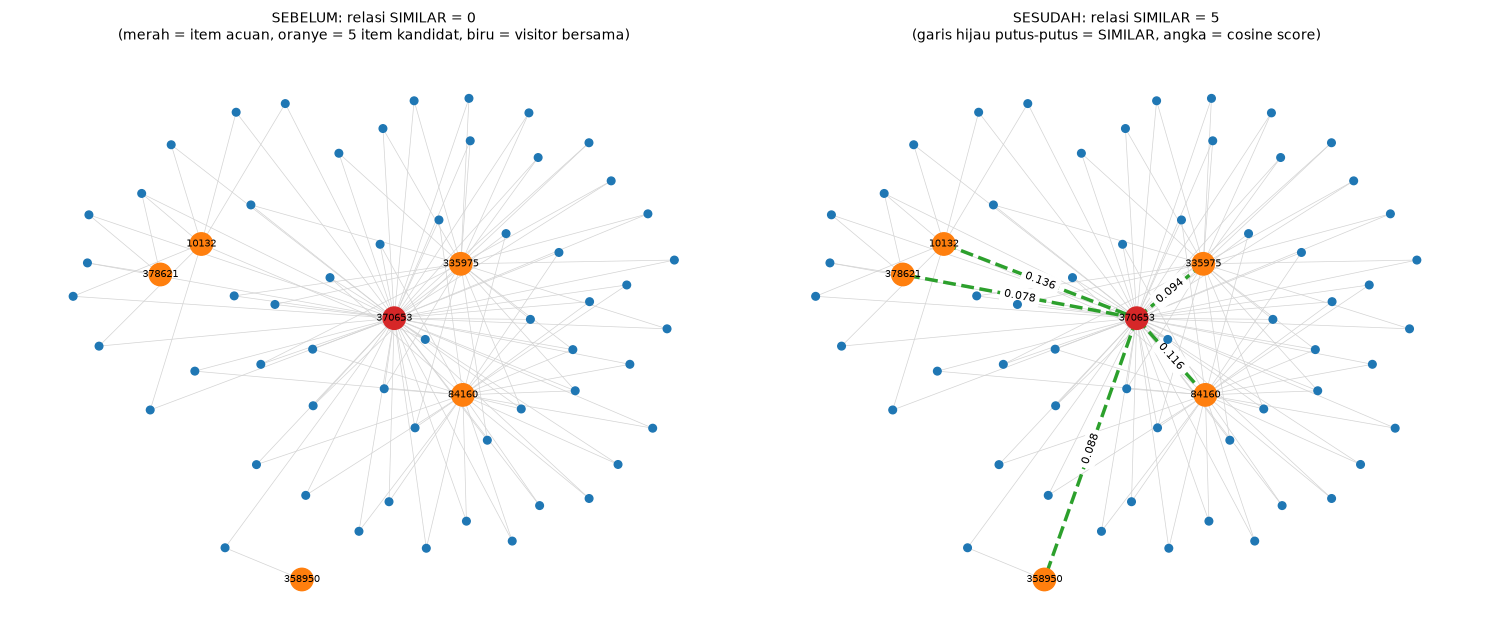

,kondisi,relasi_SIMILAR
0,sebelum,0
1,sesudah,5


In [36]:
q_sesudah = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS dari, b.itemId AS ke, s.score AS score
"""
sim_sesudah = q(q_sesudah, ref=ref_id)
jml_sesudah = int(q(q_jml_sim)["jumlah_relasi_similar"].iloc[0])

def graf_sub(sub, sim=None):
    G = nx.Graph()
    for r in sub.itertuples():
        G.add_edge(("user", r.user), ("item", r.item))
    if sim is not None:
        for r in sim.itertuples():
            G.add_edge(("item", r.dari), ("item", r.ke), score=r.score)
    return G

def gambar_graf(ax, G, judul, pos, sim=None):
    warna = []
    for n in G.nodes:
        if n == ("item", ref_id): warna.append("tab:red")
        elif n[0] == "item": warna.append("tab:orange")
        else: warna.append("tab:blue")
    ukuran = [260 if n[0] == "item" else 30 for n in G.nodes]
    sisi_biasa = [(u, v) for u, v, dt in G.edges(data=True) if "score" not in dt]
    nx.draw_networkx_edges(G, pos, edgelist=sisi_biasa, ax=ax, width=0.5, edge_color="lightgray")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=warna, node_size=ukuran)
    if sim is not None:
        sisi_sim = [(u, v) for u, v, dt in G.edges(data=True) if "score" in dt]
        nx.draw_networkx_edges(G, pos, edgelist=sisi_sim, ax=ax, width=2.5, edge_color="tab:green", style="dashed")
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8,
            edge_labels={(u, v): f"{dt['score']:.3f}" for u, v, dt in G.edges(data=True) if "score" in dt})
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7,
                            labels={n: str(n[1]) for n in G.nodes if n[0] == "item"})
    ax.set_title(judul, fontsize=10); ax.set_axis_off()

G_sesudah = graf_sub(sub_sebelum, sim_sesudah)
pos = nx.spring_layout(G_sesudah, seed=7, k=0.6)          # posisi sama untuk kedua gambar
G_sebelum = graf_sub(sub_sebelum)

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
gambar_graf(ax[0], G_sebelum, f"SEBELUM: relasi SIMILAR = {jml_sebelum}\n(merah = item acuan, oranye = 5 item kandidat, biru = visitor bersama)", pos)
gambar_graf(ax[1], G_sesudah, f"SESUDAH: relasi SIMILAR = {jml_sesudah}\n(garis hijau putus-putus = SIMILAR, angka = cosine score)", pos, sim=sim_sesudah)
plt.tight_layout(); plt.savefig(os.path.join(IMG, "graf_sebelum_sesudah.png"), dpi=120); plt.show()

pd.DataFrame({"kondisi": ["sebelum", "sesudah"], "relasi_SIMILAR": [jml_sebelum, jml_sesudah]})

# 2.2 Analytics

## No. 1: Memilih user secara acak (reproducible) dan merekomendasikan dengan KNN

**Definisi dan asumsi**
- **Pemilihan user acak:** `numpy.random.default_rng(seed=42)`. Dengan *seed* tetap hasilnya **selalu sama**. Kandidat diurutkan menurut `visitorId` lebih dulu agar urutannya deterministik.
- **Kandidat user** (agar evaluasi bermakna): ada di graf P1 dengan minimal 3 item berbeda, **dan** punya *ground truth* di P2.
- ***Ground truth*** = item yang diinteraksikan user itu di **P2**, yang **belum pernah** diinteraksikannya di P1 dan **ada di graf P1** (item baru yang mungkin direkomendasikan).
- **KNN (item-based, k = 5):** untuk setiap item yang pernah diinteraksikan user, ambil **5 item tetangga terdekat** (cosine similarity pada proyeksi Item-Item dari No. 6). Skor kandidat = Σ (bobot interaksi user × similarity). Item yang sudah pernah diinteraksikan user dibuang.
- Daftar rekomendasi **top-5** dipakai untuk evaluasi (Hit@5, NDCG@5), dan **3 item teratas** dari daftar itu yang **diiklankan**.

In [37]:
K = 5            # jumlah tetangga terdekat (KNN)
TOPN = 5         # panjang daftar rekomendasi untuk evaluasi
N_IKLAN = 3      # jumlah item yang diiklankan
SEED = 42

def tetangga_terdekat(j, k=K):
    """k item tetangga terdekat dari item indeks j berdasarkan cosine similarity (baris S)."""
    a, b = S.indptr[j], S.indptr[j + 1]
    idx, val = S.indices[a:b], S.data[a:b]
    if len(val) > k:
        o = np.argpartition(-val, k)[:k]
    else:
        o = np.arange(len(val))
    o = o[np.argsort(-val[o])]
    return idx[o], val[o]

def rekomendasi_knn(u, k=K, topn=TOPN):
    """Item-based KNN untuk user indeks u. Mengembalikan list (indeks_item, skor) terurut."""
    baris = M[u]
    sudah = set(baris.indices)
    skor = {}
    for j, bobot in zip(baris.indices, baris.data):
        tetangga, sim = tetangga_terdekat(j, k)
        for n, s in zip(tetangga, sim):
            if n in sudah:
                continue
            skor[n] = skor.get(n, 0.0) + bobot * s
    # skor sama (seri) diurutkan menurut popularitas item (derajat), lalu indeks, agar hasil deterministik
    return sorted(skor.items(), key=lambda x: (-round(x[1], 9), -deg_item[x[0]], x[0]))[:topn]

# ---- ground truth dari P2 ----
truth_p2 = p2.groupby("visitorid")["itemid"].apply(set).to_dict()
kandidat = []
for v in sorted(truth_p2):
    if v not in u_idx:
        continue
    u = u_idx[v]
    if M[u].nnz < 3:
        continue
    sudah_id = {inv_i[x] for x in M[u].indices}
    truth = {x for x in truth_p2[v] if x in i_idx and x not in sudah_id}
    if truth:
        kandidat.append((u, truth))
print(f"Jumlah user kandidat: {len(kandidat):,}")

rng = np.random.default_rng(SEED)
pilih = int(rng.integers(0, len(kandidat)))
u_pilih, truth_pilih = kandidat[pilih]
print(f"User terpilih (seed={SEED}): visitorId = {inv_u[u_pilih]} | "
      f"{M[u_pilih].nnz} item pada P1 | {len(truth_pilih)} item ground truth di P2")

Jumlah user kandidat: 805
User terpilih (seed=42): visitorId = 132397 | 4 item pada P1 | 2 item ground truth di P2


### (a) Skrip Python rekomendasi KNN
Fungsi `rekomendasi_knn` di atas adalah skripnya. Berikut hasil untuk user terpilih. Tabel pertama memperlihatkan tetangga terdekat (k = 5) dari beberapa item yang pernah dilihat user, tabel kedua daftar rekomendasi.

In [38]:
# contoh tetangga terdekat dari 3 item dengan bobot terbesar milik user
baris = M[u_pilih]
item_kuat = baris.indices[np.argsort(-baris.data)[:3]]
tabel_nn = []
for j in item_kuat:
    tetangga, sim = tetangga_terdekat(j)
    for n, s in zip(tetangga, sim):
        tabel_nn.append({"item_user": inv_i[j], "tetangga": inv_i[n], "similarity": round(float(s), 4)})
print("Tetangga terdekat (k=5) dari 3 item terkuat milik user:")
display(pd.DataFrame(tabel_nn))

rek = rekomendasi_knn(u_pilih)
rek_ids = [int(inv_i[j]) for j, _ in rek]
tabel_rek = pd.DataFrame({"peringkat": range(1, len(rek) + 1), "itemId": rek_ids,
                          "skor": [round(float(s), 4) for _, s in rek],
                          "ada_di_P2": [x in truth_pilih for x in rek_ids]})
print(f"Daftar rekomendasi top-{TOPN} untuk visitor {inv_u[u_pilih]}:")
display(tabel_rek)

Tetangga terdekat (k=5) dari 3 item terkuat milik user:


,item_user,tetangga,similarity
0,124193,340024,0.4472
1,124193,276790,0.4472
2,124193,23145,0.4472
3,124193,120898,0.4472
4,124193,184284,0.4472
5,225727,26271,0.5124
6,225727,200536,0.3431
7,225727,111637,0.3266
8,225727,110030,0.3098
9,225727,245168,0.3086


Daftar rekomendasi top-5 untuk visitor 132397:


,peringkat,itemId,skor,ada_di_P2
0,1,274811,0.5571,False
1,2,292412,0.5571,False
2,3,384130,0.5571,False
3,4,411141,0.5571,False
4,5,433356,0.5571,False


### (b) 3 item yang diiklankan untuk k = 5

In [39]:
iklan = rek_ids[:N_IKLAN]
print(f"3 item yang diiklankan kepada visitor {inv_u[u_pilih]} (k = {K}): {iklan}")
display(tabel_rek.head(N_IKLAN)[["peringkat", "itemId", "skor"]])

# (opsional) simpan rekomendasi sebagai relasi pada graf lalu tampilkan lewat Cypher
tulis("""
UNWIND $rows AS r
MATCH (v:Visitor {visitorId: $uid}), (i:Item {itemId: r.item})
MERGE (v)-[x:RECOMMENDED]->(i)
SET x.rank = r.rank, x.score = r.score, x.k = $k
""", uid=int(inv_u[u_pilih]), k=K,
     rows=[{"item": int(i), "rank": n + 1, "score": float(s)} for n, (i, s) in enumerate(zip(rek_ids, [s for _, s in rek]))])
display(q("""
MATCH (v:Visitor {visitorId: $uid})-[x:RECOMMENDED]->(i:Item)
RETURN x.rank AS peringkat, i.itemId AS itemId, x.score AS skor
ORDER BY peringkat
""", uid=int(inv_u[u_pilih])))

3 item yang diiklankan kepada visitor 132397 (k = 5): [274811, 292412, 384130]


,peringkat,itemId,skor
0,1,274811,0.5571
1,2,292412,0.5571
2,3,384130,0.5571


,peringkat,itemId,skor
0,1,274811,0.557086
1,2,292412,0.557086
2,3,384130,0.557086
3,4,411141,0.557086
4,5,433356,0.557086


## No. 2: Evaluasi rekomendasi

Dihitung dari daftar rekomendasi **top-5** untuk user terpilih, terhadap *ground truth* P2.

- **Hit@5** = 1 jika **minimal satu** item rekomendasi (top-5) ada di *ground truth*, selain itu 0.
- **DCG@5** = Σ relᵢ / log₂(i + 1), dengan i = peringkat (mulai 1) dan relᵢ = 1 bila item peringkat ke-i ada di *ground truth*. Item benar di peringkat atas bernilai lebih besar.
- **IDCG@5** = DCG ideal: semua item benar menempati peringkat teratas (sebanyak min(|ground truth|, 5)).
- **NDCG@5** = DCG@5 / IDCG@5 (0 sampai 1).

In [40]:
def hit_ndcg(rekomendasi, truth, kk=5):
    rekomendasi = list(rekomendasi)[:kk]
    hit = int(any(r in truth for r in rekomendasi))
    dcg = sum(1.0 / np.log2(pos + 2) for pos, r in enumerate(rekomendasi) if r in truth)       # pos mulai 0 -> log2(i+1) dgn i = pos+1
    idcg = sum(1.0 / np.log2(pos + 2) for pos in range(min(len(truth), kk)))
    return hit, dcg, idcg, (dcg / idcg if idcg > 0 else 0.0)

hit, dcg, idcg, ndcg = hit_ndcg(rek_ids, truth_pilih, 5)

detail = pd.DataFrame({
    "peringkat": range(1, len(rek_ids) + 1), "itemId": rek_ids,
    "rel": [int(x in truth_pilih) for x in rek_ids],
    "diskon 1/log2(i+1)": [round(1 / np.log2(i + 1), 4) for i in range(1, len(rek_ids) + 1)],
})
detail["kontribusi DCG"] = (detail["rel"] * detail["diskon 1/log2(i+1)"]).round(4)
display(detail)
print(f"Ground truth user: {len(truth_pilih)} item")
print(f"(a) Hit@5  = {hit}")
print(f"(b) NDCG@5 = {ndcg:.4f}   (DCG@5 = {dcg:.4f}, IDCG@5 = {idcg:.4f})")

,peringkat,itemId,rel,diskon 1/log2(i+1),kontribusi DCG
0,1,274811,0,1.0000,0.0
1,2,292412,0,0.6309,0.0
2,3,384130,0,0.5000,0.0
3,4,411141,0,0.4307,0.0
4,5,433356,0,0.3869,0.0


Ground truth user: 2 item
(a) Hit@5  = 0
(b) NDCG@5 = 0.0000   (DCG@5 = 0.0000, IDCG@5 = 1.6309)


### Interpretasi dan evaluasi pembanding
Hasil untuk **satu user** sangat bergantung pada user yang terpilih. Pada data *e-commerce* yang sangat *sparse* (mayoritas user hanya 1 sampai 2 item), nilai 0 pada satu user adalah hal yang wajar.
Agar kesimpulan tidak bergantung pada satu sampel, di bawah dihitung **rata-rata Hit@5 dan NDCG@5 pada 300 user acak** (seed sama) untuk membandingkan:
**Item-KNN** (yang dipakai di atas), **User-KNN** (k = 5 tetangga user), dan ***baseline* Populer** (5 item terpopuler yang belum pernah dilihat user).

In [41]:
Xu = l2_normalisasi_baris(M)                                  # vektor user ter-normalisasi

def rekomendasi_user_knn(u, k=K, topn=TOPN):
    sims = (Xu @ Xu[u].T).toarray().ravel()
    sims[u] = -1
    nn = np.argpartition(-sims, k)[:k]
    nn = [x for x in nn[np.argsort(-sims[nn])] if sims[x] > 0]
    if not nn:
        return []
    skor = np.asarray(M[nn].T @ sims[nn]).ravel()
    skor[list(set(M[u].indices))] = 0
    return [int(x) for x in np.argsort(-skor)[:topn] if skor[x] > 0]

populer = np.argsort(-deg_item)[:50]
def rekomendasi_populer(u, topn=TOPN):
    sudah = set(M[u].indices)
    return [int(x) for x in populer if x not in sudah][:topn]

rng_eval = np.random.default_rng(SEED)
sampel = rng_eval.choice(len(kandidat), size=min(300, len(kandidat)), replace=False)

hasil = {"Item-KNN (k=5)": [], "User-KNN (k=5)": [], "Populer (baseline)": []}
for p in tqdm(sampel, desc="Evaluasi"):
    u, truth = kandidat[p]
    daftar = {
        "Item-KNN (k=5)": [int(inv_i[j]) for j, _ in rekomendasi_knn(u)],
        "User-KNN (k=5)": [int(inv_i[j]) for j in rekomendasi_user_knn(u)],
        "Populer (baseline)": [int(inv_i[j]) for j in rekomendasi_populer(u)],
    }
    for nama, rec in daftar.items():
        h, _, _, n = hit_ndcg(rec, truth, 5)
        hasil[nama].append((h, n, len(rec)))

ringkas = pd.DataFrame({nama: {"Hit@5 (rata-rata)": np.mean([x[0] for x in v]),
                                "NDCG@5 (rata-rata)": np.mean([x[1] for x in v]),
                                "rata-rata panjang daftar": np.mean([x[2] for x in v])}
                         for nama, v in hasil.items()}).T
print(f"Evaluasi pada {len(sampel)} user acak (seed {SEED}):")
display(ringkas.round(4))

Evaluasi:   0%|          | 0/300 [00:00<?, ?it/s]

Evaluasi: 100%|██████████| 300/300 [00:04<00:00, 67.40it/s]

Evaluasi pada 300 user acak (seed 42):


,Hit@5 (rata-rata),NDCG@5 (rata-rata),rata-rata panjang daftar
Item-KNN (k=5),0.0267,0.0076,4.68
User-KNN (k=5),0.0400,0.0174,1.61
Populer (baseline),0.0033,0.0005,5.00


### Catatan akurasi (jujur terhadap hasil)
Pada 300 user acak, **User-KNN** memperoleh Hit@5 = 0,0400 dan NDCG@5 = 0,0174, sedikit **lebih tinggi** daripada **Item-KNN** (Hit@5 = 0,0267 dan NDCG@5 = 0,0076). Dengan 300 user, selisih ini setara sekitar 12 hit dibanding 8 hit, sehingga **belum cukup kuat** untuk menyimpulkan metode mana yang lebih akurat. Keduanya jauh di atas *baseline* Populer (Hit@5 = 0,0033).

Pemilihan proyeksi **Item-Item** pada No. 6 didasarkan pada **efisiensi** (simpul dan sisi lebih sedikit, memori lebih kecil), kesesuaian dengan tujuan merekomendasikan item, dan daftar rekomendasi yang hampir selalu terisi penuh (rata-rata 4,68 item, sedangkan User-KNN hanya 1,61), bukan pada klaim akurasi yang lebih tinggi.


## Ringkasan

In [42]:
display(Markdown(f"""
| Bagian | Hasil |
|---|---|
| Periode | P1 = {P1[0]} s.d. {P1[1]} ; P2 = {P2[0]} s.d. {P2[1]} |
| Graf P1 | {n_visitor:,} Visitor, {n_item:,} Item, {len(p1):,} relasi |
| Proyeksi terpilih | Item-Item ({st_ii['n']:,} simpul, {st_ii['sisi']:,} sisi) lebih ringkas dari User-User ({st_uu['n']:,} simpul, {st_uu['sisi']:,} sisi) |
| Item acuan similarity | {ref_id} (top-5 ditulis sebagai relasi `SIMILAR`) |
| User acak (seed {SEED}) | visitorId {inv_u[u_pilih]} |
| 3 item diiklankan (k = 5) | {iklan} |
| Hit@5 / NDCG@5 (user terpilih) | {hit} / {ndcg:.4f} |
| Hit@5 / NDCG@5 rata-rata (Item-KNN, {len(sampel)} user) | {ringkas.loc['Item-KNN (k=5)','Hit@5 (rata-rata)']:.4f} / {ringkas.loc['Item-KNN (k=5)','NDCG@5 (rata-rata)']:.4f} |
"""))
driver.close()


| Bagian | Hasil |
|---|---|
| Periode | P1 = 2015-05-15 s.d. 2015-05-28 ; P2 = 2015-05-29 s.d. 2015-06-04 |
| Graf P1 | 163,126 Visitor, 80,778 Item, 304,718 relasi |
| Proyeksi terpilih | Item-Item (80,778 simpul, 1,335,142 sisi) lebih ringkas dari User-User (163,126 simpul, 1,585,929 sisi) |
| Item acuan similarity | 370653 (top-5 ditulis sebagai relasi `SIMILAR`) |
| User acak (seed 42) | visitorId 132397 |
| 3 item diiklankan (k = 5) | [274811, 292412, 384130] |
| Hit@5 / NDCG@5 (user terpilih) | 0 / 0.0000 |
| Hit@5 / NDCG@5 rata-rata (Item-KNN, 300 user) | 0.0267 / 0.0076 |
